Import & Load

In [11]:
import sys
import os
sys.path.append(os.path.abspath(".."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.modeling import evaluate_model

In [12]:
df = pd.read_csv("../data/processed/dataset_final.csv")
df = df.sort_values("date")

dates = df["date"].values

In [13]:
y_test = np.load("../model/model_eks1/y_test.npy")
y_pred = np.load("../model/model_eks1/y_pred.npy")

import json
with open("../model/model_eks1/history.json", "r") as f:
    history = json.load(f)

Plot Predict & Actual

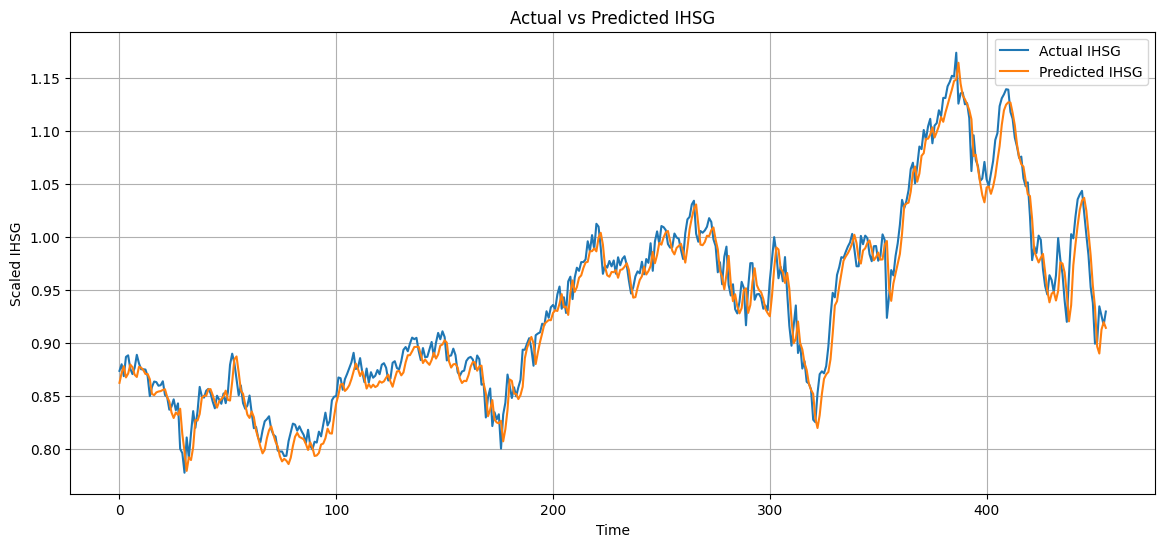

In [14]:
plt.figure(figsize=(14,6))

plt.plot(y_test, label="Actual IHSG")
plt.plot(y_pred, label="Predicted IHSG")

plt.title("Actual vs Predicted IHSG")
plt.xlabel("Time")
plt.ylabel("Scaled IHSG")
plt.legend()
plt.grid(True)
plt.show()

Check Overfitting

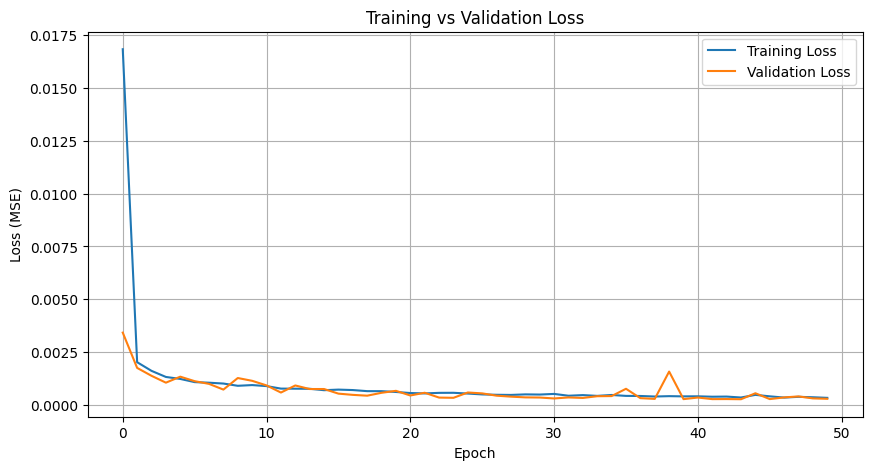

In [15]:
plt.figure(figsize=(10,5))

plt.plot(history["loss"], label="Training Loss")
plt.plot(history["val_loss"], label="Validation Loss")

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.legend()
plt.grid(True)
plt.show()

Residual Analysis

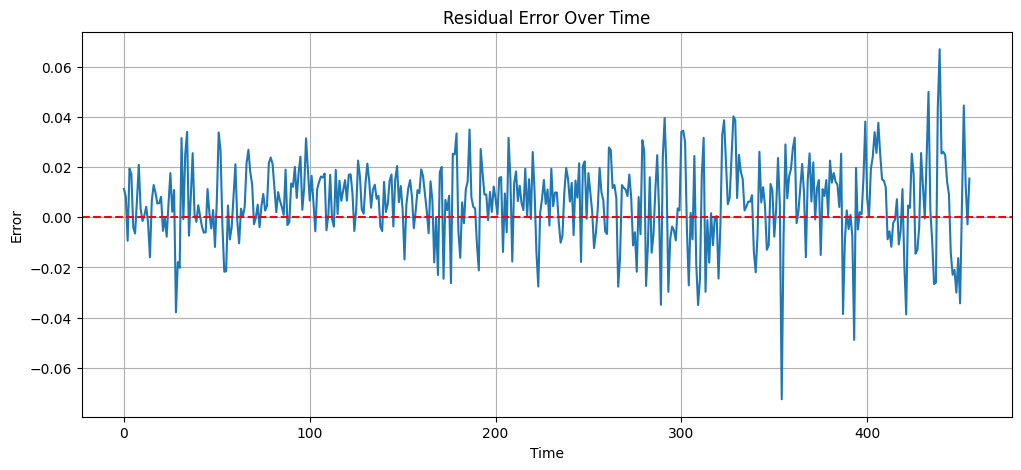

In [16]:
residuals = y_test.flatten() - y_pred.flatten()

plt.figure(figsize=(12,5))
plt.plot(residuals)
plt.axhline(0, color="red", linestyle="--")
plt.title("Residual Error Over Time")
plt.xlabel("Time")
plt.ylabel("Error")
plt.grid(True)
plt.show()

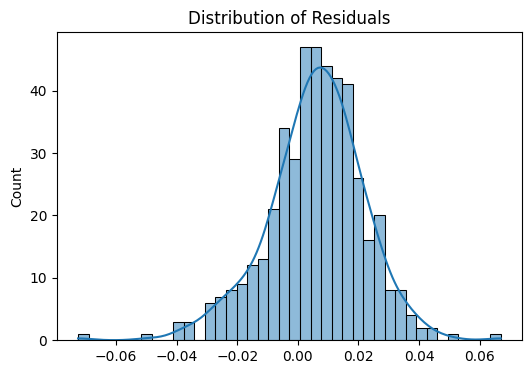

In [17]:
import seaborn as sns

plt.figure(figsize=(6,4))
sns.histplot(residuals, bins=40, kde=True)
plt.title("Distribution of Residuals")
plt.show()